# Gait asymmetry in transfemoral amputees across walking speeds

**Question:** when a person with an above-knee amputation walks faster, does the asymmetry between the intact and the prosthetic limb increase?

**Why it matters:** people with an amputation tend to load the intact limb more, and in the long term this is associated with joint pain and osteoarthritis. Understanding whether the asymmetry increases with speed helps to understand how much more intense activities, such as sport, may overload the intact limb.

**Data:** open dataset by Hood et al. (2020), *Scientific Data*: 18 individuals with a unilateral above-knee amputation, walking on an instrumented treadmill at 5 speeds. [Paper](https://www.nature.com/articles/s41597-020-0494-7) · [Data on figshare](https://doi.org/10.6084/m9.figshare.c.4962305)

**Author:** Martina Agostini, BSc Biomedical Engineering, Politecnico di Milano

## 1. Setup

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import glob, os, subprocess
import requests
import numpy as np
import pandas as pd
import scipy.io
from scipy import stats
import matplotlib.pyplot as plt

x = np.linspace(0, 100, 1001)   # common x axis: 0–100% of the gait cycle

## 2. Data download

In [21]:
# list of files in the figshare dataset
response = requests.get("https://api.figshare.com/v2/articles/10308443")
info = response.json()

for f in info["files"]:
    print(f["name"], "-", round(f["size"] / 1e6, 1), "MB")
    print("   link:", f["download_url"])

TF15.zip - 845.8 MB
   link: https://ndownloader.figshare.com/files/18733529
TF16.zip - 989.7 MB
   link: https://ndownloader.figshare.com/files/18733532
TF17.zip - 704.1 MB
   link: https://ndownloader.figshare.com/files/18733523
TF18.zip - 650.7 MB
   link: https://ndownloader.figshare.com/files/18733526
TF19.zip - 643.5 MB
   link: https://ndownloader.figshare.com/files/18733541
TF20.zip - 750.8 MB
   link: https://ndownloader.figshare.com/files/18733547
TF11.zip - 502.7 MB
   link: https://ndownloader.figshare.com/files/18733544
TF12.zip - 1060.5 MB
   link: https://ndownloader.figshare.com/files/18733559
TF13.zip - 648.3 MB
   link: https://ndownloader.figshare.com/files/18733556
TF14.zip - 1280.8 MB
   link: https://ndownloader.figshare.com/files/18733562
plot_eachspeed_comp_sides.m - 0.0 MB
   link: https://ndownloader.figshare.com/files/18733442
plotshaded.m - 0.0 MB
   link: https://ndownloader.figshare.com/files/18733445
example_plotting_script.m - 0.0 MB
   link: https://ndo

In [22]:
!mkdir -p /content/drive/MyDrive/mini_progetto_amputati/dati
%cd /content/drive/MyDrive/mini_progetto_amputati/dati

!wget -q -O "README.docx" "https://ndownloader.figshare.com/files/20554929"
!wget -q -O "Subject_Information.xlsx" "https://ndownloader.figshare.com/files/21836562"
!wget -q -O "example_plotting_script.m" "https://ndownloader.figshare.com/files/18733448"

/content/drive/MyDrive/mini_progetto_amputati/dati


In [23]:
# download each subject's zip, keep only the processed .mat file, delete the zip
data_folder = '/content/drive/MyDrive/mini_progetto_amputati/dati'
info = requests.get("https://api.figshare.com/v2/articles/10308443").json()

for f in info['files']:
    name = f['name']
    if not name.endswith('.zip'):
        continue
    subject = name.replace('.zip', '')
    if os.path.exists(f'{data_folder}/{subject}_DATA.mat'):
        print(subject, 'already downloaded, skipping')
        continue
    print('Downloading', subject, '...')
    subprocess.run(['wget', '-q', '-O', '/content/tmp.zip', f['download_url']])
    subprocess.run(['unzip', '-q', '-o', '/content/tmp.zip', '*.mat', '-d', '/content/extracted'])
    for mat in glob.glob('/content/extracted/**/*.mat', recursive=True):
        subprocess.run(['cp', mat, data_folder])
    subprocess.run(['rm', '-rf', '/content/tmp.zip', '/content/extracted'])
    print(subject, 'done')

print('Finished!')

TF15 already downloaded, skipping
TF16 already downloaded, skipping
TF17 already downloaded, skipping
TF18 already downloaded, skipping
TF19 already downloaded, skipping
TF20 already downloaded, skipping
TF11 already downloaded, skipping
TF12 already downloaded, skipping
TF13 already downloaded, skipping
TF14 already downloaded, skipping
TF01 already downloaded, skipping
TF02 already downloaded, skipping
TF10 already downloaded, skipping
TF05 already downloaded, skipping
TF06 already downloaded, skipping
TF07 already downloaded, skipping
TF08 already downloaded, skipping
TF09 already downloaded, skipping
Finished!


## 3. Data structure

In [24]:
path = '/content/drive/MyDrive/mini_progetto_amputati/dati/TF01_DATA.mat'
data = scipy.io.loadmat(path, simplify_cells=True)
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'TF01'])


In [25]:
def show_structure(obj, name='TF01', level=0, max_level=4):
    indent = '    ' * level
    if isinstance(obj, dict):
        print(f"{indent}{name}  (dict, {len(obj)} keys)")
        if level < max_level:
            for key, value in obj.items():
                show_structure(value, key, level + 1, max_level)
    elif isinstance(obj, np.ndarray):
        print(f"{indent}{name}  (array, shape {obj.shape})")
    else:
        print(f"{indent}{name}  ({type(obj).__name__}: {obj})")

show_structure(data['TF01'])

TF01  (dict, 2 keys)
    data  (dict, 5 keys)
        speed_0p6  (dict, 2 keys)
            ipsilateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
                hip  (dict, 2 keys)
                knee  (dict, 2 keys)
            contralateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
                hip  (dict, 2 keys)
                knee  (dict, 2 keys)
        speed_0p8  (dict, 2 keys)
            ipsilateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
                hip  (dict, 2 keys)
                knee  (dict, 2 keys)
            contralateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
                hip  (dict, 2 keys)
                knee  (dict, 2 keys)
        speed_1p0  (dict, 2 keys)
            ipsilateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
                hip  (dict, 2 keys)
                knee  (dict, 2 keys)
            contralateral  (dict, 3 keys)
                ankle  (dict, 2 keys)
             

In [26]:
intact_knee = data['TF01']['data']['speed_1p0']['contralateral']['knee']
show_structure(intact_knee, name='knee (intact, 1.0 m/s)')

knee (intact, 1.0 m/s)  (dict, 2 keys)
    position  (dict, 3 keys)
        raw  (array, shape (1001, 34))
        avg  (array, shape (1001,))
        stdev  (array, shape (1001,))
    moment  (dict, 3 keys)
        raw  (array, shape (1001, 34))
        avg  (array, shape (1001,))
        stdev  (array, shape (1001,))


### Dataset structure

Each subject has a file `TFxx_DATA.mat` (e.g. `TF01_DATA.mat`, 19 MB) containing a dictionary with two parts.

**1. `info` – subject characteristics**
- `k_level`: mobility level (2 = slower group, 3 = more mobile group)
- `weight`: body mass (kg)
- `height`: height (cm)
- `amputation_side`: amputation side (`right` / `left`)

Example TF01: k_level 3, 64.9 kg, 178 cm, right-side amputation.

**2. `data` – gait measurements**

Path to a value:

`data['TF01']['data'][speed][side][joint][quantity][version]`

- **speed**: `speed_0p6`, `speed_0p8`, `speed_1p0`, `speed_1p2`, `speed_1p4` ("p" stands for the decimal point: `0p6` = 0.6 m/s). K2 subjects walked at lower speeds (0.4–0.8 m/s).
- **side**: `ipsilateral` = prosthetic side, `contralateral` = intact side
- **joint**: `ankle`, `knee`, `hip`
- **quantity**: `position` = joint angle, `moment` = joint moment
- **version**:
  - `raw`: array (1001 × N), i.e. 1001 points of the gait cycle for N recorded strides (e.g. 34)
  - `avg`: mean across strides, array (1001,)
  - `stdev`: standard deviation across strides, array (1001,)

**Observations**
- Data are already time-normalised to the gait cycle: 1001 points = 0–100% of the cycle, one point every 0.1%. No interpolation needed.
- Mean and standard deviation are already computed.
- No ground reaction forces or stance times: the analysis uses joint angles and moments.
- Units: verified below (degrees and Nm/kg).

Example: hip moment on the prosthetic side at 1.4 m/s

`data['TF01']['data']['speed_1p4']['ipsilateral']['hip']['moment']['avg']`

### Information from the paper (Methods)

- 18 subjects, 9 K2 (speeds 0.4–0.8 m/s) and 9 K3 (0.6–1.4 m/s). Main analysis on the K3 group.
- For each speed: 5 trials of at least 10 strides. Gait events (heel strike, toe off) detected automatically.
- Markers at 200 Hz, forces at 1000 Hz. Low-pass Butterworth filter: 6 Hz markers, 15 Hz forces. Processing in Visual3D.
- Some subjects used the handrails (not instrumented): check who in Subject_Information.xlsx.
- Prosthetic side less reliable: prosthetic shank mass estimated (1/3 of an intact shank) and hip joint centre affected by movement at the socket-tissue interface. The intact side is more reliable.
- Units confirmed by the dataset's plotting functions (see below).

In [27]:
knee = data['TF01']['data']['speed_1p0']['contralateral']['knee']

print("Intact knee angle: min", round(knee['position']['avg'].min(), 2),
      " max", round(knee['position']['avg'].max(), 2))
print("Intact knee moment: min", round(knee['moment']['avg'].min(), 2),
      " max", round(knee['moment']['avg'].max(), 2))

Intact knee angle: min -65.65  max 2.37
Intact knee moment: min -0.3  max 0.8


In [28]:
# check the axis labels in the dataset's MATLAB plotting function to confirm the units
%cd /content/drive/MyDrive/mini_progetto_amputati/dati
!wget -q -O "plot_eachspeed_comp_sides.m" "https://ndownloader.figshare.com/files/18733442"
!grep -i "label" plot_eachspeed_comp_sides.m

/content/drive/MyDrive/mini_progetto_amputati/dati
            ylabel('Joint Position (deg)')
            ylabel('Joint Moment (Nm/kg)')
            ylabel 'error'
            ylabel('Joint Position (deg)')
            ylabel('Joint Moment (Nm/kg)')
            ylabel 'error'
        xlabel('% Stride')


**Units (confirmed by the dataset's plotting functions):**

- angles in degrees;
- moments in Nm/kg (already normalised to body mass);
- x axis in % of the gait cycle (1001 points).

**Observed sign convention:** knee flexion is negative (peak about −66° for the intact knee at 1.0 m/s).

## 4. First analysis: TF01

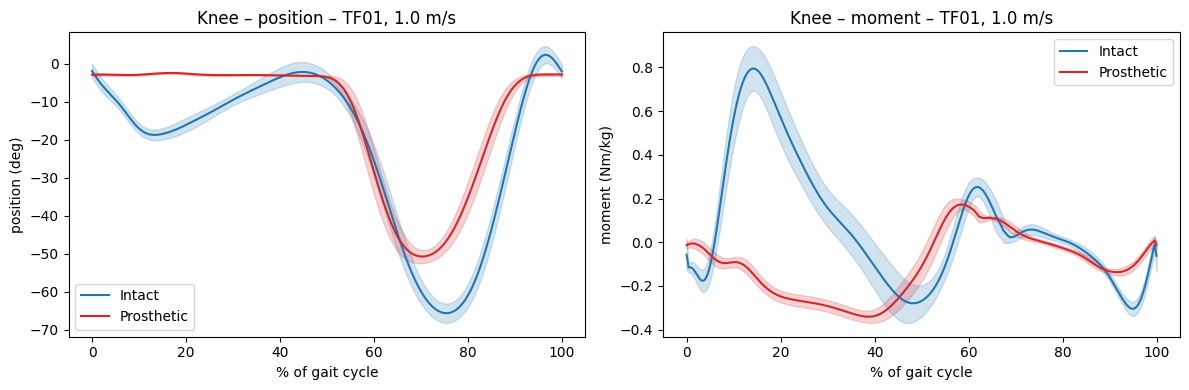

In [29]:
speed = 'speed_1p0'
intact = data['TF01']['data'][speed]['contralateral']['knee']
prosthetic = data['TF01']['data'][speed]['ipsilateral']['knee']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, quantity, unit in zip(axes, ['position', 'moment'], ['deg', 'Nm/kg']):
    for side, label, color in [(intact, 'Intact', 'tab:blue'), (prosthetic, 'Prosthetic', 'tab:red')]:
        mean = side[quantity]['avg']
        sd = side[quantity]['stdev']
        ax.plot(x, mean, color=color, label=label)
        ax.fill_between(x, mean - sd, mean + sd, color=color, alpha=0.2)
    ax.set_xlabel('% of gait cycle')
    ax.set_ylabel(f'{quantity} ({unit})')
    ax.set_title(f'Knee – {quantity} – TF01, 1.0 m/s')
    ax.legend()

plt.tight_layout()
plt.show()

**Knee angle** (left)

**Intact side (blue):** right after heel strike the knee flexes by about 18°, around 12% of the cycle. This is impact absorption: the knee acts as a shock absorber. Then, in swing, it flexes up to about 65° around 75% of the cycle, so that the foot clears the ground.

**Prosthetic side (red):** in stance the knee stays almost straight, at about −3°, for the whole first half of the cycle. No shock absorption. This is expected: many prostheses lock the knee in stance to prevent it from buckling. In swing it flexes less, about 50°, and slightly earlier.

**Knee moment** (right)

**Intact side:** there is a large positive peak, about 0.8 Nm/kg, around 14% of the cycle. This is when the quadriceps work to slow down the body as the knee flexes.

**Prosthetic side:** this peak is missing. The moment is negative for most of stance, down to about −0.3 Nm/kg: the prosthetic knee is pushed into extension and stays locked.

**Sign convention:** the early-stance peak on the intact side is the classic knee extensor moment, and it is positive. So in this dataset positive moment = extensor, and for angles flexion is negative.

**The intact limb does all the shock absorption at impact, while the prosthetic knee stays rigid → overload**

**Does this difference grow when walking faster?**

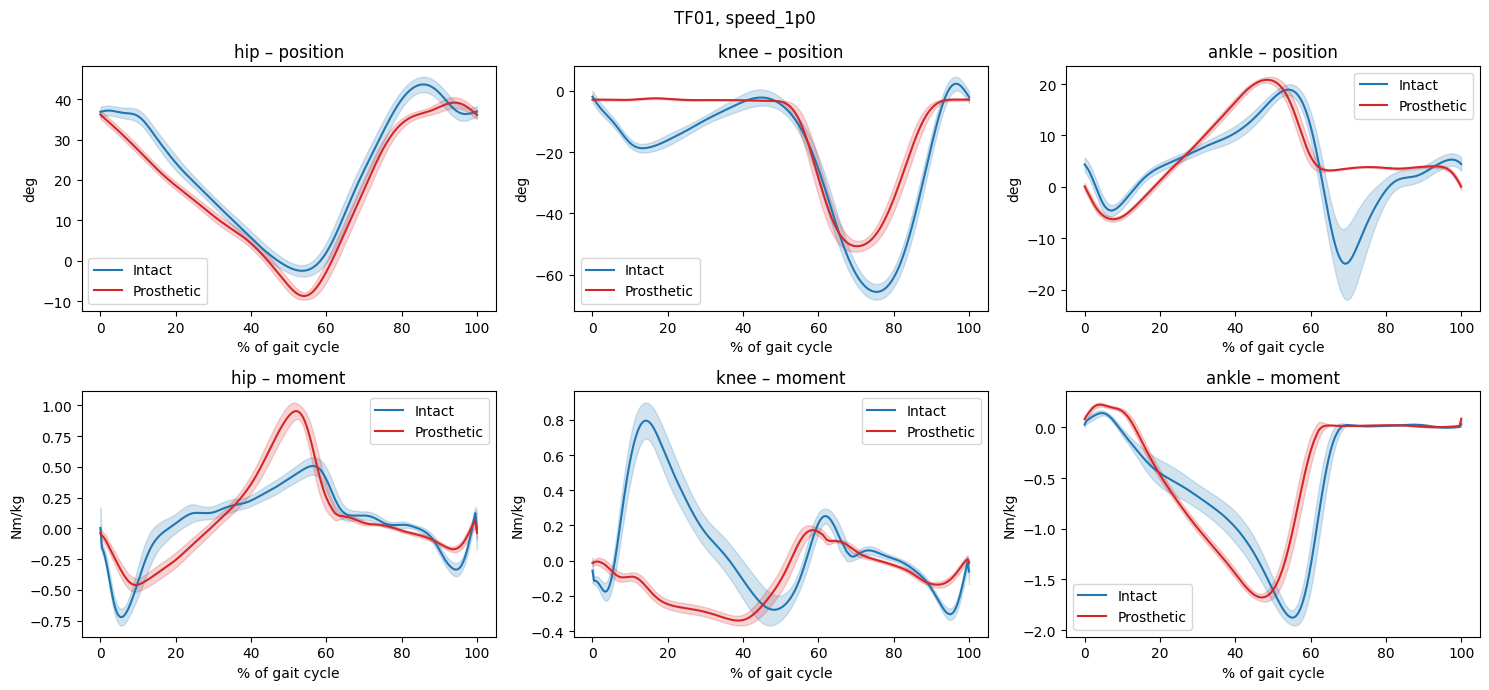

In [30]:
def plot_joints(subject, speed):
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for col, joint in enumerate(['hip', 'knee', 'ankle']):
        for row, (quantity, unit) in enumerate([('position', 'deg'), ('moment', 'Nm/kg')]):
            ax = axes[row, col]
            for side, label, color in [('contralateral', 'Intact', 'tab:blue'),
                                       ('ipsilateral', 'Prosthetic', 'tab:red')]:
                d = data[subject]['data'][speed][side][joint][quantity]
                ax.plot(x, d['avg'], color=color, label=label)
                ax.fill_between(x, d['avg'] - d['stdev'], d['avg'] + d['stdev'],
                                color=color, alpha=0.2)
            ax.set_title(f'{joint} – {quantity}')
            ax.set_xlabel('% of gait cycle')
            ax.set_ylabel(unit)
            ax.legend()
    fig.suptitle(f'{subject}, {speed}')
    plt.tight_layout()
    plt.show()

plot_joints('TF01', 'speed_1p0')

### Observations – TF01, 1.0 m/s

#### Hip

**Angle:** similar shapes on both sides. The prosthetic side extends slightly more in mid-cycle, about −8° vs −3°.

**Moment:** two clear peaks, on both sides.

- **Early stance (5–10%), negative:** intact about −0.7, prosthetic about −0.45 Nm/kg.
  This is the moment with which the hip muscles support the body at impact: **higher peak on the intact side**.
- **Late stance (50–55%), positive:** prosthetic about 0.95, intact about 0.5 Nm/kg.
  Here **the prosthetic side has almost twice the peak**: the hip has to pull the prosthesis forward into swing, because the prosthesis provides no active push.
  This is a **compensation** typical of above-knee amputees.

#### Knee

The **intact side absorbs the impact**: it flexes by about 18° in early stance and produces an extensor moment of about 0.8 Nm/kg.

The **prosthetic side stays rigid**: no stance flexion and no extensor peak.

#### Ankle

**Angle:** on the intact side, at the end of stance (about 70%), the ankle plantarflexes to −15° to push off.
**On the prosthetic side this movement is missing:** the prosthetic foot stays at about +4°.

**Moment:** both sides show a large negative peak at the end of stance, intact about −1.9 and prosthetic about −1.7 Nm/kg.
This is the **push-off** (plantarflexor) moment. The prosthetic foot, which works like a spring, produces a similar moment but reaches it earlier.

#### Sign conventions

- Angles: **flexion negative**, extension positive.
- Knee moment: **positive = extensor**.

---

### Selected parameters

Only peaks where **both sides have a clear value with the same sign** are used, so that the symmetry index is meaningful.

| Parameter | Window (% of cycle) | Value taken | TF01 at 1.0 m/s (by eye) |
| --- | --- | --- | --- |
| Peak hip moment, early stance | 0–20% | absolute value of the minimum | intact 0.7 · prosthetic 0.45 |
| Peak hip moment, late stance | 30–70% | maximum | intact 0.5 · prosthetic 0.95 |
| Peak ankle moment (push-off) | 30–70% | absolute value of the minimum | intact 1.9 · prosthetic 1.7 |
| Peak knee flexion in swing | 50–90% | absolute value of the minimum angle | intact 65° · prosthetic 50° |

**Additional parameter, intact side only:**

| Parameter | Window | Why |
| --- | --- | --- |
| Peak intact knee extensor moment | 0–30% | It does not exist on the prosthetic side, so no symmetry index. But it is the most direct measure of **how much load the intact knee takes**: does it grow with speed? |

**Reading the symmetry index (SI):**
- SI = 0%: perfect symmetry;
- positive SI: the intact side has a higher value;
- negative SI: the prosthetic side has a higher value.

## 5. Parameters and symmetry index

In [31]:
def symmetry_index(intact, prosthetic):
    return (intact - prosthetic) / (0.5 * (intact + prosthetic)) * 100

def peak(curve, start, end, kind):
    i0, i1 = int(start * 10), int(end * 10)   # % to index: 1001 points -> 10 points per 1%
    segment = curve[i0:i1 + 1]
    return segment.max() if kind == 'max' else abs(segment.min())

params = {
    'hip_early_stance':   ('hip',   'moment',   0, 20, 'min'),
    'hip_late_stance':    ('hip',   'moment',  30, 70, 'max'),
    'ankle_push_off':     ('ankle', 'moment',  30, 70, 'min'),
    'knee_swing_flexion': ('knee',  'position', 50, 90, 'min'),
}

subject = 'TF01'
for speed in data[subject]['data'].keys():
    print(f'\n{speed}')
    d = data[subject]['data'][speed]
    for name, (joint, qty, start, end, kind) in params.items():
        s = peak(d['contralateral'][joint][qty]['avg'], start, end, kind)
        p = peak(d['ipsilateral'][joint][qty]['avg'], start, end, kind)
        print(f'  {name:24s} intact {s:6.2f}  prosthetic {p:6.2f}  SI {symmetry_index(s, p):6.1f}%')
    ext = peak(d['contralateral']['knee']['moment']['avg'], 0, 30, 'max')
    print(f'  {"intact_knee_extensor":24s} intact {ext:6.2f}')


speed_0p6
  hip_early_stance         intact   0.56  prosthetic   0.18  SI  100.6%
  hip_late_stance          intact   0.35  prosthetic   0.69  SI  -65.2%
  ankle_push_off           intact   1.20  prosthetic   1.55  SI  -25.3%
  knee_swing_flexion       intact  63.01  prosthetic  40.51  SI   43.5%
  intact_knee_extensor     intact   0.22

speed_0p8
  hip_early_stance         intact   0.50  prosthetic   0.30  SI   50.0%
  hip_late_stance          intact   0.51  prosthetic   0.83  SI  -47.1%
  ankle_push_off           intact   1.62  prosthetic   1.56  SI    3.9%
  knee_swing_flexion       intact  64.79  prosthetic  46.02  SI   33.9%
  intact_knee_extensor     intact   0.52

speed_1p0
  hip_early_stance         intact   0.72  prosthetic   0.46  SI   44.2%
  hip_late_stance          intact   0.51  prosthetic   0.95  SI  -61.0%
  ankle_push_off           intact   1.88  prosthetic   1.68  SI   11.2%
  knee_swing_flexion       intact  65.65  prosthetic  50.74  SI   25.6%
  intact_knee_extenso

### Preliminary results – TF01 (K3), 0.6–1.4 m/s

**1. Intact knee: load increases strongly with speed**

| Speed (m/s) | 0.6 | 0.8 | 1.0 | 1.2 | 1.4 |
| --- | --- | --- | --- | --- | --- |
| Intact knee extensor moment (Nm/kg) | 0.22 | 0.52 | 0.80 | 1.18 | 1.49 |

The intact knee extensor moment increases **almost 7-fold** between 0.6 and 1.4 m/s, while the prosthetic knee does not contribute to shock absorption. **Limitation:** this moment also increases with speed in non-amputees; a comparison with a control group would be needed.

**2. Ankle: push-off asymmetry increases with speed**

| Speed (m/s) | 0.6 | 0.8 | 1.0 | 1.2 | 1.4 |
| --- | --- | --- | --- | --- | --- |
| Intact (Nm/kg) | 1.20 | 1.62 | 1.88 | 2.10 | 2.39 |
| Prosthetic (Nm/kg) | 1.55 | 1.56 | 1.68 | 1.73 | 1.84 |
| SI | −25% | 4% | 11% | 19% | 26% |

The intact ankle **doubles** its push-off, while the prosthetic foot increases only slightly: being a spring with fixed stiffness, it cannot push harder. **The extra push-off comes from the intact limb.** This is the result that best supports the hypothesis.

**3. Hip, late stance: the prosthetic side always compensates**

SI between **−40% and −65%** at all speeds: the prosthetic hip has a higher peak, because it has to pull the prosthesis forward. Values increase with speed on both sides.

**4. Hip, early stance: unstable SI for small values**

The SI decreases from 100% to 20%, but **both values increase**: the prosthetic one increases more. The 100% at 0.6 m/s comes from small values (0.56 vs 0.18). **Limitation:** with small values the SI exaggerates differences.

**5. Knee flexion in swing: the prosthetic knee adapts**

The SI decreases from 43% to 5%: at high speeds the prosthetic knee flexes almost as much as the intact one (62° vs 66°). Probably an effect of the prosthetic knee control (check the knee type in Subject_Information.xlsx). This is a **movement** parameter, not a load parameter.

**Summary:** for the load parameters, as speed increases **the intact limb takes on more and more of the load**, while the prosthesis cannot keep up.

**Note:** this is a single subject. To be verified on the whole K3 group (9 subjects).

## 6. All subjects

In [32]:
mat_files = sorted(glob.glob('/content/drive/MyDrive/mini_progetto_amputati/dati/*.mat'))
print(len(mat_files), 'files found')
for f in mat_files:
    print(f.split('/')[-1])

18 files found
TF01_DATA.mat
TF02_DATA.mat
TF05_DATA.mat
TF06_DATA.mat
TF07_DATA.mat
TF08_DATA.mat
TF09_DATA.mat
TF10_DATA.mat
TF11_DATA.mat
TF12_DATA.mat
TF13_DATA.mat
TF14_DATA.mat
TF15_DATA.mat
TF16_DATA.mat
TF17_DATA.mat
TF18_DATA.mat
TF19_DATA.mat
TF20_DATA.mat


In [33]:
rows = []

for f in mat_files:
    content = scipy.io.loadmat(f, simplify_cells=True)
    subject = [k for k in content.keys() if not k.startswith('__')][0]   # e.g. 'TF01'
    s_data = content[subject]
    k_level = s_data['info']['k_level']

    for speed_name, d in s_data['data'].items():
        v = float(speed_name.replace('speed_', '').replace('p', '.'))   # 'speed_1p4' -> 1.4

        for name, (joint, qty, start, end, kind) in params.items():
            s = peak(d['contralateral'][joint][qty]['avg'], start, end, kind)
            p = peak(d['ipsilateral'][joint][qty]['avg'], start, end, kind)
            rows.append({'subject': subject, 'k_level': k_level, 'speed': v,
                         'parameter': name, 'intact': s, 'prosthetic': p,
                         'SI': symmetry_index(s, p)})

        ext = peak(d['contralateral']['knee']['moment']['avg'], 0, 30, 'max')
        rows.append({'subject': subject, 'k_level': k_level, 'speed': v,
                     'parameter': 'intact_knee_extensor', 'intact': ext,
                     'prosthetic': None, 'SI': None})

table = pd.DataFrame(rows)
print(table.shape)
table.head(10)

(445, 7)


,subject,k_level,speed,parameter,intact,prosthetic,SI
0,TF01,3,0.6,hip_early_stance,0.555444,0.183706,100.585342
1,TF01,3,0.6,hip_late_stance,0.350983,0.690566,-65.207283
2,TF01,3,0.6,ankle_push_off,1.204475,1.552829,-25.267687
3,TF01,3,0.6,knee_swing_flexion,63.013950,40.506503,43.484059
4,TF01,3,0.6,intact_knee_extensor,0.222699,NaN,NaN
5,TF01,3,0.8,hip_early_stance,0.497269,0.298496,49.957820
6,TF01,3,0.8,hip_late_stance,0.514706,0.831769,-47.095298
7,TF01,3,0.8,ankle_push_off,1.619407,1.557989,3.865932
8,TF01,3,0.8,knee_swing_flexion,64.791774,46.021709,33.876861
9,TF01,3,0.8,intact_knee_extensor,0.523916,NaN,NaN


NaN (Not a Number) means "missing value". For `intact_knee_extensor` there is no prosthetic value and no SI, because this parameter is measured on the intact side only. This is expected.

In [34]:
# number of speeds per subject
count = table.groupby(['subject', 'k_level'])['speed'].nunique()
print(count)

# number of subjects per group
print('\nSubjects per group:')
print(table.groupby('k_level')['subject'].nunique())

# save the table to Drive
table.to_csv('/content/drive/MyDrive/mini_progetto_amputati/results.csv', index=False)
print('\nTable saved to results.csv')

subject  k_level
TF01     3          5
TF02     2          4
TF05     2          5
TF06     2          5
TF07     3          5
TF08     3          5
TF09     2          5
TF10     2          5
TF11     3          5
TF12     2          5
TF13     3          5
TF14     2          5
TF15     3          5
TF16     3          5
TF17     3          5
TF18     2          5
TF19     3          5
TF20     2          5
Name: speed, dtype: int64

Subjects per group:
k_level
2    9
3    9
Name: subject, dtype: int64

Table saved to results.csv


- 9 K2 and 9 K3 subjects, as reported in the paper;
- the subject with one speed missing is TF02 (K2);
- the K3 group includes TF01, TF07, TF08, TF11, TF13, TF15, TF16, TF17 and TF19, all with the 5 speeds complete: 0.6, 0.8, 1.0, 1.2 and 1.4 m/s.

## 7. K3 group

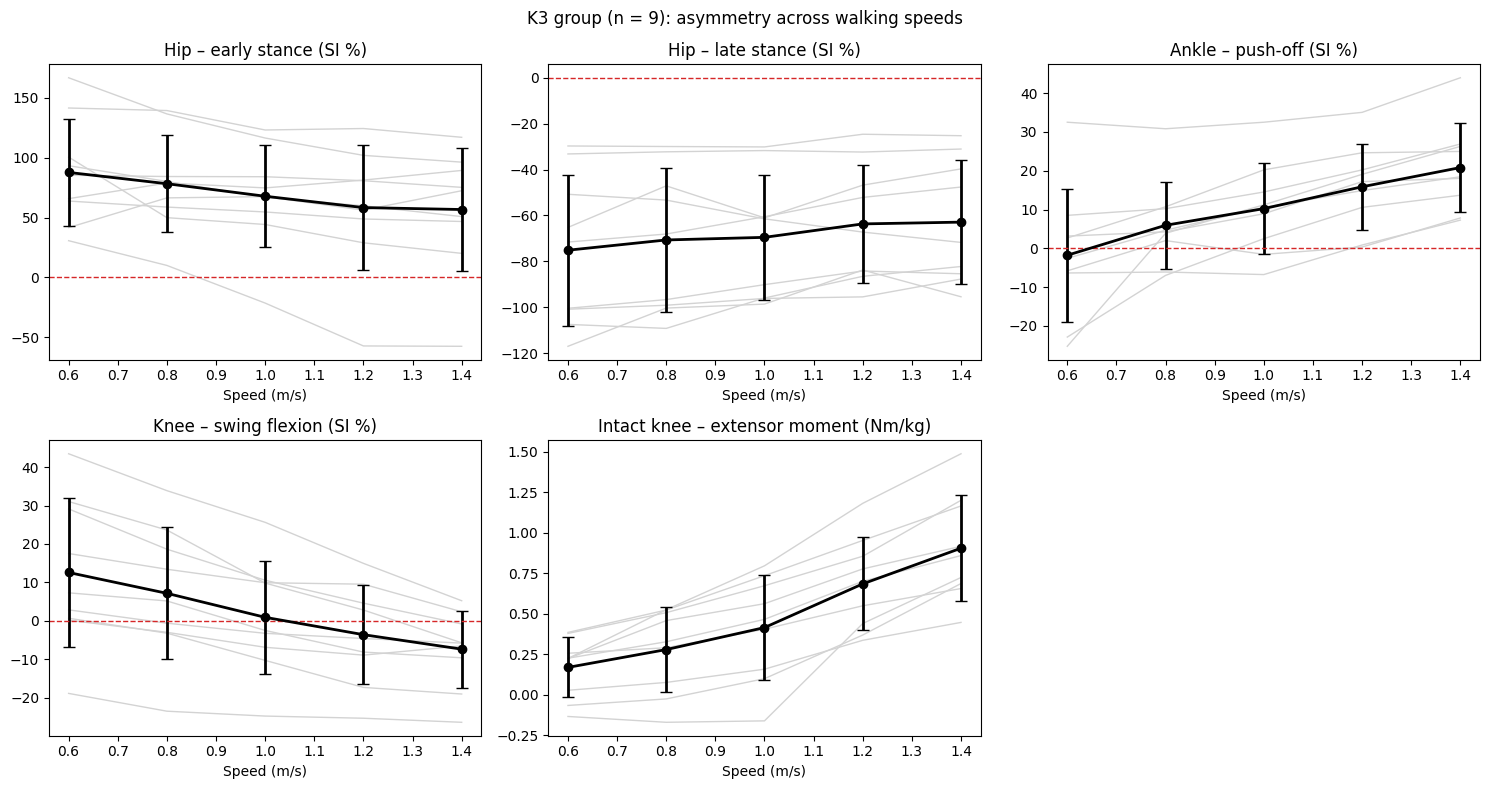

In [35]:
k3 = table[table['k_level'] == 3]

titles = {
    'hip_early_stance':     'Hip – early stance (SI %)',
    'hip_late_stance':      'Hip – late stance (SI %)',
    'ankle_push_off':       'Ankle – push-off (SI %)',
    'knee_swing_flexion':   'Knee – swing flexion (SI %)',
    'intact_knee_extensor': 'Intact knee – extensor moment (Nm/kg)',
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (param, title) in zip(axes, titles.items()):
    d = k3[k3['parameter'] == param]
    column = 'intact' if param == 'intact_knee_extensor' else 'SI'

    # one thin grey line per subject
    for subj, ds in d.groupby('subject'):
        ax.plot(ds['speed'], ds[column], color='lightgray', linewidth=1)

    # group mean ± standard deviation
    stat = d.groupby('speed')[column].agg(['mean', 'std'])
    ax.errorbar(stat.index, stat['mean'], yerr=stat['std'],
                color='black', marker='o', capsize=4, linewidth=2)

    if column == 'SI':
        ax.axhline(0, color='tab:red', linestyle='--', linewidth=1)   # perfect symmetry
    ax.set_title(title)
    ax.set_xlabel('Speed (m/s)')

axes[-1].axis('off')   # sixth panel left empty
fig.suptitle('K3 group (n = 9): asymmetry across walking speeds')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/mini_progetto_amputati/k3_SI_vs_speed.png', dpi=200)
plt.show()

### K3 group results (n = 9), speeds 0.6–1.4 m/s

**Intact knee – extensor moment:** the prosthetic knee stays rigid and does not absorb the impact, so the intact knee does it all. The peak increases from about 0.17 to 0.90 Nm/kg, in all subjects. *Limitation: it also increases with speed in non-amputees.*

**Hip, late stance:** the prosthetic side has a higher peak at all speeds (SI between about −75% and −63%), because it has to pull the prosthesis forward. The asymmetry decreases slightly at higher speeds.

**Ankle, push-off:** at 0.6 m/s the two sides are similar; at higher speeds the intact ankle greatly increases its push-off, while the prosthetic foot barely changes. The SI increases from about −2% to +21%, in almost all subjects.

**Hip, early stance:** on average a higher peak on the intact side, but large variability between subjects. Not reliable.

**Knee, swing flexion:** the SI decreases from about +12% to −7%; at high speeds the prosthetic knee flexes as much as the intact one. Movement parameter, not load.

**Interpretation:** as speed increases, the intact limb absorbs the impacts (knee) and provides the extra push-off (ankle), while the prosthetic side compensates with the hip. Load shifts more and more onto the intact limb and the prosthetic-side hip, precisely the joints that tend to suffer in the long term in amputees *(to be supported with references in the report)*.

## 8. Statistical test

In [36]:
print(f'{"parameter":24s} {"mean slope":>12s} {"subj. increasing":>17s} {"p-value":>9s}')

for param in titles.keys():
    d = k3[k3['parameter'] == param]
    column = 'intact' if param == 'intact_knee_extensor' else 'SI'

    slopes = []
    for subj, ds in d.groupby('subject'):
        slope, intercept = np.polyfit(ds['speed'], ds[column], 1)   # linear regression
        slopes.append(slope)
    slopes = np.array(slopes)

    t, p = stats.ttest_1samp(slopes, 0)
    increasing = (slopes > 0).sum()
    print(f'{param:24s} {slopes.mean():12.2f} {increasing:>13d} / 9 {p:9.4f}')

parameter                  mean slope  subj. increasing   p-value
hip_early_stance               -40.99             2 / 9    0.0449
hip_late_stance                 15.73             8 / 9    0.0458
ankle_push_off                  27.57             9 / 9    0.0007
knee_swing_flexion             -25.35             0 / 9    0.0012
intact_knee_extensor             0.94             9 / 9    0.0000


### Statistical test on the slopes

For each subject of the K3 group I computed, with `np.polyfit`, the slope of the line relating each parameter to walking speed. Then I used a one-sample t-test to check whether the mean of the 9 slopes differs from zero.

**Robust results**

- **Intact knee extensor moment:** slope +0.94 Nm/kg per m/s, increasing in 9/9 subjects (p < 0.001). The load on the intact knee increases with speed, in all subjects.
- **Ankle, push-off:** SI slope +27.6 points per m/s, 9/9 subjects (p = 0.0007). The asymmetry increases in all subjects, because the intact ankle increases its push-off while the prosthetic foot barely changes.
- **Knee, swing flexion:** SI slope −25.4 points per m/s, 0/9 subjects increasing (p = 0.0012). The asymmetry decreases in all subjects: the prosthetic knee gets closer to the intact one.

**Borderline results**

The two hip parameters have p-values close to 0.05 (0.045 for early stance and 0.046 for late stance). With a Bonferroni correction for 5 tests (threshold 0.05 / 5 = 0.01) they are no longer significant.

**Conclusion**

In the K3 group, as speed increases:
- the intact knee bears an increasing load (9/9 subjects);
- the intact ankle provides an increasing share of the push-off (9/9 subjects);
- the prosthesis adapts in movement (knee flexion in swing), but not in push-off.

Therefore, for the load parameters, the asymmetry against the intact limb increases with walking speed.

## 9. K2 vs K3

In [37]:
k2 = table[table['k_level'] == 2]

print('K2 group (0.4–0.8 m/s)')
print(f'{"parameter":24s} {"mean slope":>12s} {"subj. increasing":>17s} {"p-value":>9s}')

for param in titles.keys():
    d = k2[k2['parameter'] == param]
    column = 'intact' if param == 'intact_knee_extensor' else 'SI'

    slopes = []
    for subj, ds in d.groupby('subject'):
        slope, intercept = np.polyfit(ds['speed'], ds[column], 1)
        slopes.append(slope)
    slopes = np.array(slopes)

    t, p = stats.ttest_1samp(slopes, 0)
    increasing = (slopes > 0).sum()
    print(f'{param:24s} {slopes.mean():12.2f} {increasing:>11d} / {len(slopes)} {p:9.4f}')

K2 group (0.4–0.8 m/s)
parameter                  mean slope  subj. increasing   p-value
hip_early_stance                25.39           5 / 9    0.3723
hip_late_stance                284.07           8 / 9    0.2344
ankle_push_off                  -2.13           5 / 9    0.9265
knee_swing_flexion             -55.57           1 / 9    0.0068
intact_knee_extensor             0.15           7 / 9    0.0623


In [38]:
common = table[table['speed'].isin([0.6, 0.8])]

print(f'{"parameter":24s} {"speed":>6s} {"K2 mean":>9s} {"K3 mean":>9s} {"p-value":>9s}')

for param in titles.keys():
    column = 'intact' if param == 'intact_knee_extensor' else 'SI'
    for v in [0.6, 0.8]:
        d = common[(common['parameter'] == param) & (common['speed'] == v)]
        g2 = d[d['k_level'] == 2][column].dropna()
        g3 = d[d['k_level'] == 3][column].dropna()
        t, p = stats.ttest_ind(g2, g3, equal_var=False)   # Welch's t-test
        print(f'{param:24s} {v:6.1f} {g2.mean():9.2f} {g3.mean():9.2f} {p:9.4f}')

parameter                 speed   K2 mean   K3 mean   p-value
hip_early_stance            0.6     86.29     87.76    0.9584
hip_early_stance            0.8    100.79     78.32    0.3101
hip_late_stance             0.6   -120.35    -75.13    0.5546
hip_late_stance             0.8    -69.92    -70.67    0.9830
ankle_push_off              0.6     17.15     -1.79    0.0483
ankle_push_off              0.8     16.19      5.93    0.1442
knee_swing_flexion          0.6     31.25     12.57    0.0810
knee_swing_flexion          0.8     16.98      7.14    0.2906
intact_knee_extensor        0.6      0.15      0.17    0.8950
intact_knee_extensor        0.8      0.17      0.28    0.3515


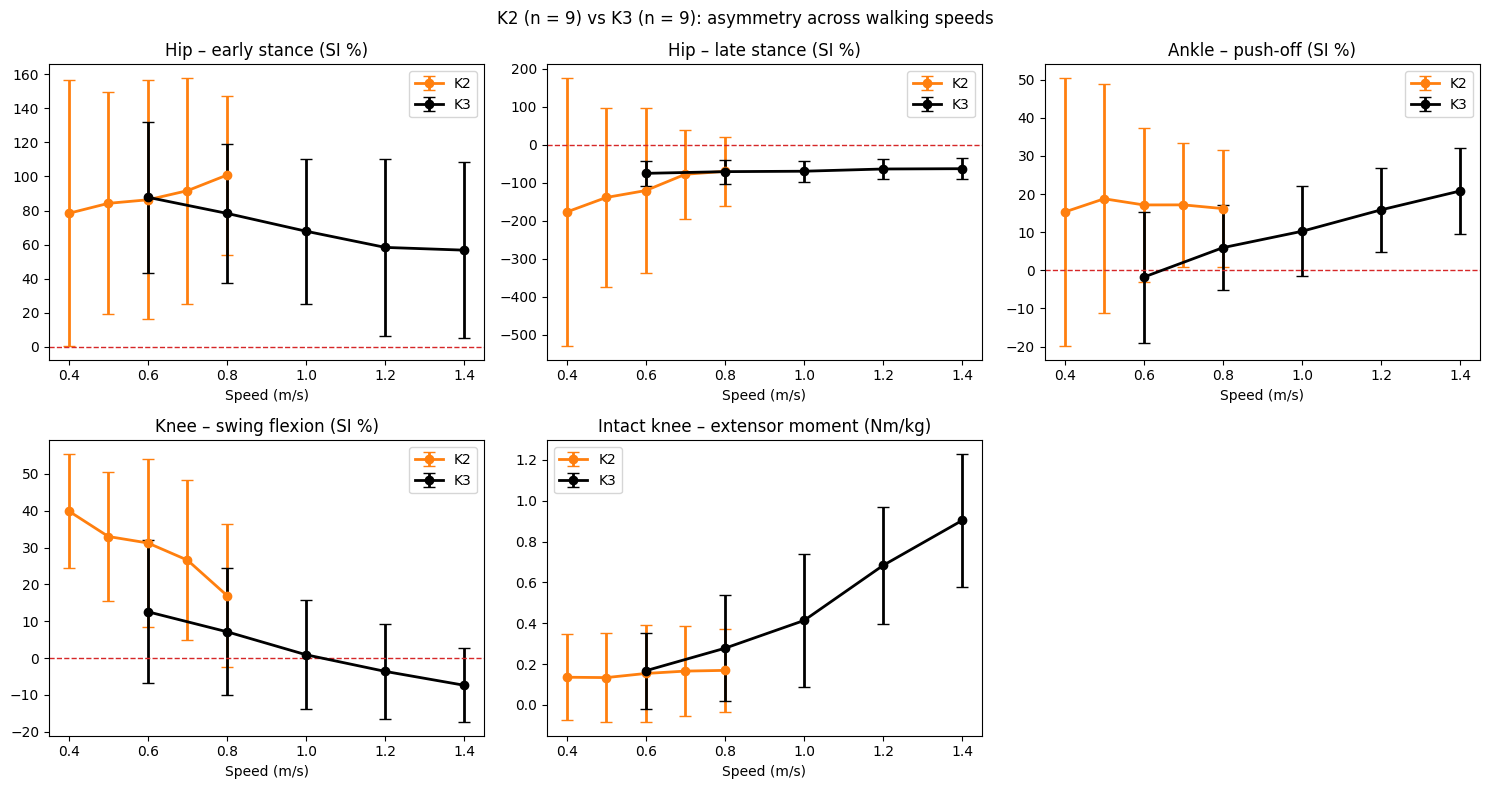

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (param, title) in zip(axes, titles.items()):
    d = table[table['parameter'] == param]
    column = 'intact' if param == 'intact_knee_extensor' else 'SI'
    for k, color, label in [(2, 'tab:orange', 'K2'), (3, 'black', 'K3')]:
        stat = d[d['k_level'] == k].groupby('speed')[column].agg(['mean', 'std'])
        ax.errorbar(stat.index, stat['mean'], yerr=stat['std'], color=color,
                    marker='o', capsize=4, linewidth=2, label=label)
    if column == 'SI':
        ax.axhline(0, color='tab:red', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Speed (m/s)')
    ax.legend()

axes[-1].axis('off')
fig.suptitle('K2 (n = 9) vs K3 (n = 9): asymmetry across walking speeds')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/mini_progetto_amputati/K2_vs_K3.png', dpi=200)
plt.show()

### K2 vs K3 – summary

I repeated the slope analysis for the K2 group (0.4–0.8 m/s) and compared the two groups at the common speeds of 0.6 and 0.8 m/s with Welch's t-test (Bonferroni threshold 0.05 / 10 = 0.005).

In the K2 group, only knee swing flexion changed significantly with speed (p = 0.007), in the same direction as in K3. The intact knee extensor moment stayed almost constant (about 0.15 Nm/kg), and the ankle push-off asymmetry remained at about +17% at all speeds. The hip late stance SI was too variable to be interpreted, because in some subjects the peak was close to zero.

At the same speeds the two groups were similar: the only p < 0.05 was the ankle SI at 0.6 m/s (p = 0.048), not significant after Bonferroni correction.

**Conclusion:** the increasing load on the intact limb seen in K3 seems related mainly to the **higher walking speeds**, rather than to the mobility level. Limitations: narrower speed range in K2, small groups (9 vs 9), and possible greater use of the handrails in K2.